# MAFFT multiple sequence alignment

Align four related classroom strings and inspect which columns are shared, variable or sparsely occupied.

A multiple sequence alignment proposes homologous columns across several sequences. A guide tree and subsequent refinement can make it tractable to align more than a single pair. A column with strong agreement but few observed bases is different from a fully occupied conserved column. Measure occupancy and within-column agreement separately.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import subprocess, shutil
import numpy as np
import matplotlib.pyplot as plt
from io import StringIO
from collections import Counter
from Bio import SeqIO
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
from genome_methods import rng_dna

## Align the strings and inspect the columns

The native MAFFT command runs on the temporary FASTA locally. Check each returned sequence by removing its gaps and looking up the original identifier.

aligned columns 62 fully occupied 53 variable among called bases 1


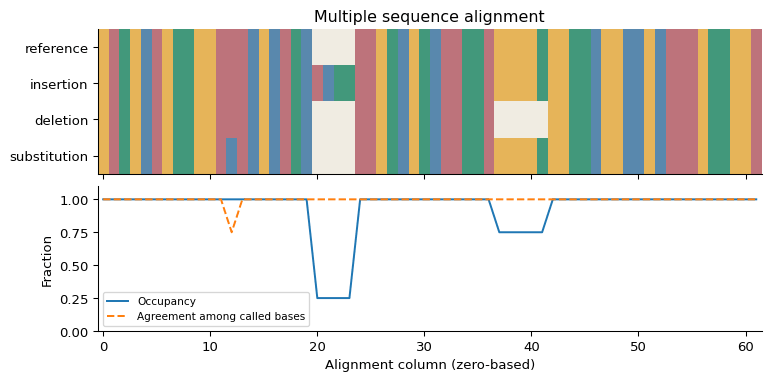

In [2]:
rng = np.random.default_rng(101)
base = rng_dna(rng, 58)
family = {
    "reference": base,
    "insertion": base[:21] + "AGGT" + base[21:],
    "deletion": base[:35] + base[40:],
    "substitution": base[:12] + ("A" if base[12] != "A" else "G") + base[13:],
}
with TemporaryDirectory() as where:
    inp = Path(where) / "family.fa"
    inp.write_text("".join(f">{k}\n{s}\n" for k, s in family.items()))
    out = subprocess.run(
        ["mafft", "--quiet", "--thread", "1", "--auto", "--nuc", str(inp)],
        check=True,
        capture_output=True,
        text=True,
    ).stdout
aligned = {r.id: str(r.seq).upper() for r in SeqIO.parse(StringIO(out), "fasta")}
assert set(aligned) == set(family) and all(
    aligned[k].replace("-", "") == s for k, s in family.items()
)
array = np.array([list(aligned[k]) for k in family])
width = array.shape[1]
occupied = (array != "-").mean(0)
agreement = []
for col in array.T:
    calls = [a for a in col if a != "-"]
    agreement.append(max(Counter(calls).values()) / len(calls))
print(
    "aligned columns",
    width,
    "fully occupied",
    sum(occupied == 1),
    "variable among called bases",
    sum(x < 1 for x in agreement),
)
from matplotlib.colors import ListedColormap

fig, (a, b) = plt.subplots(2, 1, figsize=(8, 3.9), sharex=True, constrained_layout=True)
chars = "-ACGT"
enc = np.array([[chars.index(x) for x in row] for row in array])
a.imshow(
    enc,
    cmap=ListedColormap(["#f0ece2", "#5988ad", "#e6b459", "#42987b", "#bd737b"]),
    vmin=0,
    vmax=4,
    aspect="auto",
)
a.set(yticks=range(len(family)), yticklabels=list(family), title="Multiple sequence alignment")
b.plot(occupied, label="Occupancy")
b.plot(agreement, "--", label="Agreement among called bases")
b.set(xlabel="Alignment column (zero-based)", ylabel="Fraction", ylim=(0, 1.1))
b.legend(fontsize=8)
plt.show()

## Interpreting the result

Multiple alignments can place an insertion differently in a repeated region. Preserving each input sequence does not prove that every inferred column is biologically correct.

## Exercise

Insert the same motif at two neighbouring positions in a repeat and inspect the alternative gap placements.

## References

[Katoh and Standley, MAFFT version 7 (2013)](https://doi.org/10.1093/molbev/mst010)

[MAFFT manuals and licence](https://mafft.cbrc.jp/alignment/software/)